## Plot the distribution of CR energy (densities) vs velocity 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from transform_data import get_transformed_data
from utils import get_polar_grid, get_shock_mask
from field_config import field_cmaps, field_lims, field_labels, shck_color_list, shck_tick_num, shck_ticks, field_scales

import flash_amr_tools
import h5py

In [2]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crshock"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"

# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]

In [3]:
sims = ["ISM-v30", "ISM-v30-MDiff", "ISM-v30-HDiff", "ISM-v100"]

minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
82560 82560
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 94208
Region extended to:	lower		upper
	x	-7.71419469e+19		+2.31425806e+20
	y	-7.71419469e+19		+7.71419469e+19
	z	-7.71419469e+19		+7.71419469e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00


/tmp/ipykernel_796877/131765486.py:30: RuntimeWarning: divide by zero encountered in divide
  dxs = (up_cor - low_cor) / cube_size
/tmp/ipykernel_796877/131765486.py:111: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(os.path.join(fig_dir, f"scatter_encr_r_{sim}_plt20.png"), dpi=300)
/home/kwatanabe/miniconda3/envs/crbowshocks_env/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/home/kwatanabe/miniconda3/envs/crbowshocks_env/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


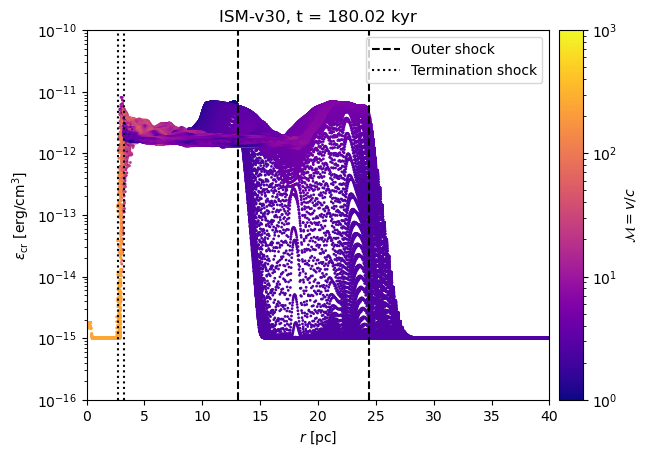

In [4]:


for isim, sim in enumerate(sims):
    if isim > 0:
        break

    fig, ax = plt.subplots()

    sim_dir = os.path.join(flash_output_dir, bowshock_config[sim]["sim_dir"])

    sim_file = os.path.join(sim_dir, "starISM_hdf5_plt_cnt_0020")
    
    blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

    pf = h5py.File(sim_file)
    ref_lvl = pf["refine level"][()][blist]
    bbox = pf["bounding box"][()][blist]
    bsize = pf["block size"][()][blist]
    time = (pf["real scalars"][()][0][1] * u.s).to_value(u.kyr)  # time in kyr

    low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]

    # extent for imshow
    extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

    # generate arrays for coordinates
    # get size of x and y
    cube_size = np.zeros(3, dtype=int)
    cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
    cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
    low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
    dxs = (up_cor - low_cor) / cube_size
    xarr = ((
        np.linspace(low_cor[0], up_cor[0], cube_size[0], endpoint=False) + 0.5 * dxs[0]
    ) * u.cm).to_value(u.pc)
    yarr = ((
        np.linspace(low_cor[1], up_cor[1], cube_size[1], endpoint=False) + 0.5 * dxs[1]
    ) * u.cm).to_value(u.pc)

    # get the radial distance array 
    X, Y = np.meshgrid(xarr, yarr, indexing="ij")
    R = np.sqrt(X**2 + Y**2)
    # flatten
    R_flat = R.flatten()

    del X, Y

    # get the encr & vel data
    encr_data = get_transformed_data(pf, "encr", blist)
    vel_data = get_transformed_data(pf, "vel", blist)

    encr_slice = flash_amr_tools.get_slice(encr_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)
    vel_slice = flash_amr_tools.get_slice(vel_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

    del encr_data, vel_data

    # flatten both
    encr_flat = encr_slice.flatten()
    vel_flat = vel_slice.flatten() / 11.8  # convert to mach number

    # plot the scatter plot
    sc = ax.scatter(R_flat, encr_flat, c=vel_flat, s=1, cmap="plasma", norm=mcolors.LogNorm(1, 1e3, clip=True))

    del vel_flat, encr_flat, R_flat

    # plot the shock position as well
    outer_shock_data = get_shock_mask(pf, blist, shock="outer")
    outer_shock_slice = flash_amr_tools.get_slice(outer_shock_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

    del outer_shock_data

    R_shock = R[outer_shock_slice > 0]

    # plot the scatter plot
    ax.axvline(np.max(R_shock), color="black", linestyle="--", label="Outer shock")
    ax.axvline(np.min(R_shock), color="black", linestyle="--")

    # plot the shock position as well
    term_shock_data = get_shock_mask(pf, blist, shock="term")
    term_shock_slice = flash_amr_tools.get_slice(term_shock_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

    del term_shock_data

    R_shock = R[term_shock_slice > 0]

   # plot the scatter plot
    ax.axvline(np.max(R_shock), color="black", linestyle=":", label="Termination shock")
    ax.axvline(np.min(R_shock), color="black", linestyle=":")

    del encr_slice, vel_slice, R_shock, outer_shock_slice, R, term_shock_slice

    

    # ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel(r"$r$ [pc]")
    ax.set_ylabel(r"$\epsilon_{\rm cr}$ [erg/cm$^3$]")
    ax.set_xlim(0, 40)
    ax.set_ylim(1e-16, 1e-10)
    ax.legend()

    # add colorbar
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = plt.colorbar(sc, cax=cax)
    cbar.set_label(r"$\mathcal{M} = v / c$")
    # cbar.ax.set_ylim(1, 50)

    ax.set_title(f"{sim}, t = {time:.2f} kyr")

    
    fig.savefig(os.path.join(fig_dir, f"scatter_encr_r_{sim}_plt20.png"), dpi=300)

minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
82560 82560
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 94208
Region extended to:	lower		upper
	x	-7.71419469e+19		+2.31425806e+20
	y	-7.71419469e+19		+7.71419469e+19
	z	-7.71419469e+19		+7.71419469e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00


/tmp/ipykernel_796877/1192485349.py:30: RuntimeWarning: divide by zero encountered in divide
  dxs = (up_cor - low_cor) / cube_size
/tmp/ipykernel_796877/1192485349.py:71: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 5e3)


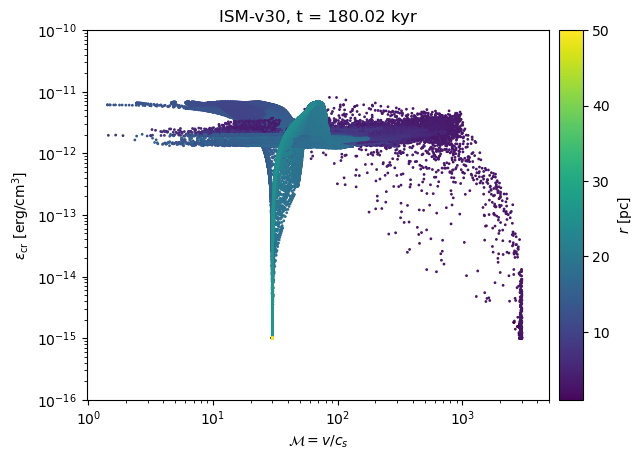

In [5]:
time = 180.0 * u.kyr # kyr

for isim, sim in enumerate(sims):
    if isim > 0:
        break

    fig, ax = plt.subplots()

    sim_dir = os.path.join(flash_output_dir, bowshock_config[sim]["sim_dir"])

    sim_file = os.path.join(sim_dir, "starISM_hdf5_plt_cnt_0020")
    
    blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

    pf = h5py.File(sim_file)
    ref_lvl = pf["refine level"][()][blist]
    bbox = pf["bounding box"][()][blist]
    bsize = pf["block size"][()][blist]
    # time = (pf["real scalars"][()][0][1] * u.s).to_value(u.kyr)  # time in kyr

    low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]

    # extent for imshow
    extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

    # generate arrays for coordinates
    # get size of x and y
    cube_size = np.zeros(3, dtype=int)
    cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
    cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
    low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
    dxs = (up_cor - low_cor) / cube_size
    xarr = ((
        np.linspace(low_cor[0], up_cor[0], cube_size[0], endpoint=False) + 0.5 * dxs[0]
    ) * u.cm).to_value(u.pc)
    yarr = ((
        np.linspace(low_cor[1], up_cor[1], cube_size[1], endpoint=False) + 0.5 * dxs[1]
    ) * u.cm).to_value(u.pc)

    # get the radial distance array 
    X, Y = np.meshgrid(xarr, yarr, indexing="ij")
    R = np.sqrt(X**2 + Y**2)
    # flatten
    R_flat = R.flatten()

    del X, Y

    # get the encr & vel data
    encr_data = get_transformed_data(pf, "encr", blist)
    vel_data = get_transformed_data(pf, "vel", blist)

    encr_slice = flash_amr_tools.get_slice(encr_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)
    vel_slice = flash_amr_tools.get_slice(vel_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

    del encr_data, vel_data

    # flatten both
    encr_flat = encr_slice.flatten()
    vel_flat = vel_slice.flatten()

    # plot the scatter plot
    sc = ax.scatter(vel_flat, encr_flat, c=R_flat, s=1, cmap="viridis", norm=mcolors.Normalize(0, 50, clip=True))

    del vel_flat, encr_flat, R_flat

    

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel(r"$\mathcal{M} = v / c_s$")
    ax.set_ylabel(r"$\epsilon_{\rm cr}$ [erg/cm$^3$]")
    ax.set_xlim(0, 5e3)
    ax.set_ylim(1e-16, 1e-10)

    # add colorbar
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = plt.colorbar(sc, cax=cax)
    cbar.set_label(r"$r$ [pc]")
    cbar.ax.set_ylim(1, 50)

    ax.set_title(f"{sim}, t = {time:.2f} kyr")

    
    fig.savefig(os.path.join(fig_dir, f"scatter_encr_mach_{sim}_plt20.png"), dpi=300)

cumulative distribution, i.e. sort in bins of mach number, and get the number of encr there

In [4]:
def find_hdf5_file_from_time(time, sim_dir):
    """
    Find the HDF5 file corresponding to the given time in the simulation directory.
    """
    for file in os.listdir(sim_dir):
        if file.find("hdf5") != -1:
            pf = h5py.File(os.path.join(sim_dir, file), "r")
            time_from_file = (pf['real scalars'][0][1] * u.s).to(u.kyr)
            if np.isclose(time, time_from_file.value, atol=0.1):
                return os.path.join(sim_dir, file)
            
    return None

In [5]:
time = 180 # kyr

minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
82560 82560
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 94208
Region extended to:	lower		upper
	x	-7.71419469e+19		+2.31425806e+20
	y	-7.71419469e+19		+7.71419469e+19
	z	-7.71419469e+19		+7.71419469e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00
minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71

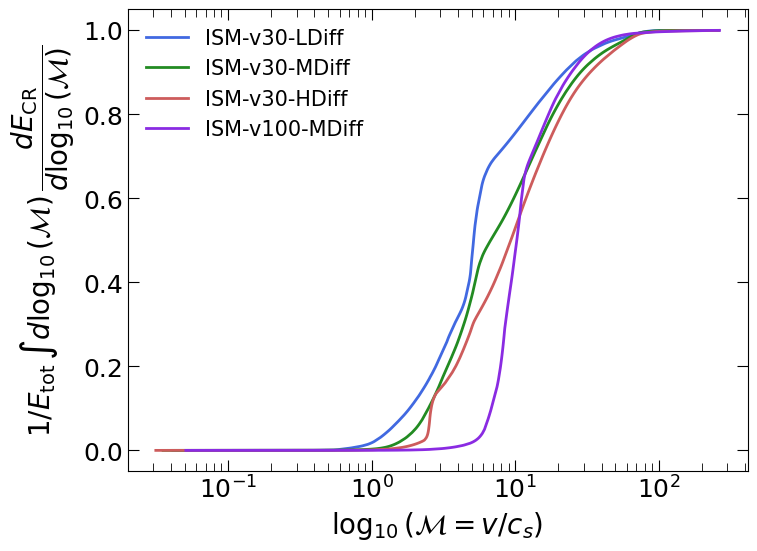

In [6]:
fig, ax = plt.subplots(figsize=(8,6))

for isim, sim in enumerate(sims):

    sim_dir = os.path.join(flash_output_dir, bowshock_config[sim]["sim_dir"])

    sim_file = find_hdf5_file_from_time(time, sim_dir)
    
    blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

    pf = h5py.File(sim_file)
    ref_lvl = pf["refine level"][()][blist]
    bbox = pf["bounding box"][()][blist]
    bsize = pf["block size"][()][blist]
    # time = (pf["real scalars"][()][0][1] * u.s).to_value(u.kyr)  # time in kyr

    low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]

    # extent for imshow
    extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

    # generate arrays for coordinates
    # get size of x and y
    cube_size = np.zeros(3, dtype=int)
    cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
    cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
    cube_size[2] = int(bns[2]) * 2 ** (brefs[0] - brefs[1] + 3)
    low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
    dxs = (up_cor - low_cor) / cube_size

    # get the encr & vel data
    encr_data = get_transformed_data(pf, "encr", blist)
    mach_data = get_transformed_data(pf, "vel", blist).value / 11.8 

    idces = np.argsort(mach_data.flatten())
    encr_sorted = encr_data.flatten()[idces] * u.erg * u.cm**-3
    mach_sorted = mach_data.flatten()[idces]  # convert to mach number

    # compute the cumulative sum
    encr_cumsum = np.cumsum(encr_sorted.to(u.erg * u.pc**-3) * (dxs[0] * dxs[1] * dxs[2] * u.cm**3).to(u.pc**3)) # in erg/cm^3 * pc^2 = erg/cm
    # normalise
    encr_cumsum /= encr_cumsum[-1]

    ax.plot(mach_sorted, encr_cumsum, linewidth=2.0, color=bowshock_config[sim]["color"], label=bowshock_config[sim]["label"])

    del encr_data, mach_data, encr_sorted, mach_sorted, idces, encr_cumsum
ax.set_xscale("log")
ax.set_xlabel(r"$\log_{10}(\mathcal{M} = v / c_s)$", fontsize=20)
# ax.set_ylabel("Normalised Cumulative Distribution of $E_\mathrm{CR}$", fontsize=20)
ax.set_ylabel(r"$1 / E_\mathrm{tot} \, \int d \log_{10}(\mathcal{M}) \,  \dfrac{d E_\mathrm{CR} }{d \log_{10}(\mathcal{M})} $", fontsize=20)

ax.tick_params(
                axis="both",
                direction="in",
                which="major",
                size=8,
                labelsize=18,
                top=True,
                right=True,
            )

ax.tick_params(
                axis="both",
                direction="in",
                which="minor",
                size=6,
                labelsize=18,
                top=True,
                right=True,
            )

ax.legend(frameon=False, loc="upper left", framealpha=0.0, fontsize=20, prop={"size": 15})
fig.savefig(os.path.join(fig_dir, "cumsum_encr_mach_plt20.png"), dpi=300, bbox_inches="tight")

In [8]:
fig.savefig(os.path.join(fig_dir, "cumsum_encr_mach_plt20.pdf"), dpi=300, bbox_inches="tight")